# Fashion MNIST — Neural Network Practical Tasks

**Level:** Beginner → Intermediate  
**Tools:** Python, TensorFlow/Keras, Matplotlib  
**Goal:** Experiment with a Neural Network and understand what changes its performance.

## Before You Start

- Load the **Fashion MNIST** dataset.
- Keep a separate **validation set** from the training data (or use `validation_split=0.2`).
- Normalize image pixels to the range **0–1**.
- Use the **same train/validation split** for all comparisons.
- Evaluate final models on `x_test` only after choosing the model settings.
- Change **one setting at a time** unless the task says otherwise.

**Baseline model (use for most tasks):**

| Layer | Configuration |
|---|---|
| Input | `28 × 28` |
| Flatten | Convert image to 784 values |
| Dense | 32 neurons, `relu` |
| Dense (output) | 10 neurons, `softmax` |

**Compile:** `optimizer='adam'`, `loss='sparse_categorical_crossentropy'`, `metrics=['accuracy']`  
**Default training:** `epochs=10`, `batch_size=32`.

---

## Task 1 — Explore the Dataset

1. Print the shapes of the training and testing data.
2. Print the number of classes and their names.
3. Display **10 images** with their labels.
4. Count the training images in each class.

**Answer:** Why do we normalize pixel values? Is the dataset balanced?

## Task 2 — Train a Baseline Model

1. Build the baseline model shown above.
2. Train it for **10 epochs**.
3. Report training accuracy, validation accuracy, and final test accuracy.
4. Plot `loss` vs. `val_loss` and `accuracy` vs. `val_accuracy`.

**Answer:** What is the purpose of `Flatten`, `ReLU`, and `Softmax`?

## Task 3 — Analyze Predictions

1. Select **3 test images**: at least **one correct** and **one incorrect** prediction (if available).
2. Show each image with its **true label** and **predicted label**.
3. Show the predicted probability for the chosen class.

**Answer:** How does the image move through the model (forward pass)? For an incorrect prediction, what might make the two clothing classes confusing? **Do not claim to know the exact reason from the prediction alone.**

## Task 4 — Compare Epochs

Train a **fresh model each time** with **5, 10, and 20 epochs**. Keep everything else the same.

1. Plot training/validation loss and accuracy for each run.
2. Compare the **best validation accuracy**.
3. Check whether validation performance stops improving while training performance keeps improving.

**Answer:** Which run shows signs of overfitting? Is more training always better?

## Task 5 — EarlyStopping Experiment

Use **40 epochs** as the maximum. Compare:

- **Run A:** Without `EarlyStopping`.
- **Run B:** With `EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)`.
- **Run C:** With `EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)`.

1. Record the number of epochs actually trained.
2. Compare the best validation loss and final validation accuracy.

**Answer:** What does `patience=3`,`5` mean? Why might EarlyStopping help?

## Task 6 — Hidden Neurons Experiment

Train fresh models with **16, 32, and 128 neurons** in the hidden layer.

1. Keep epochs, batch size, optimizer, and data split fixed.
2. Compare training and validation accuracy.
3. Record training time if possible.

**Answer:** Did adding neurons always improve validation accuracy? What is the trade-off?

## Task 7 — Batch Size Experiment

Train fresh models using `batch_size` values **8, 32, and 128**.

1. Keep the architecture, optimizer, and epochs fixed.
2. Compare validation accuracy and time per epoch.
3. Plot the loss curves.

**Answer:** How does batch size change the number of weight updates per epoch? Which batch size worked best in your experiment?

## Task 8 — Optimizer Comparison

Use the same architecture and training settings with:

- `SGD(learning_rate=0.01)`
- `SGD(learning_rate=0.01, momentum=0.9)`
- `Adam(learning_rate=0.001)`

1. Plot the training and validation loss curves.
2. Compare validation accuracy after 10 epochs.

**Answer:** Which optimizer improved fastest in your results? How is Momentum different from basic SGD?

**Optional challenge:** Try `AdamW` and compare it with Adam.

## Task 9 — Activation Function Comparison

Replace the **hidden-layer** ReLU with:

- `tanh`
- `gelu` **(optional)**

Keep **Softmax in the output layer** unchanged.

1. Train each version with the same settings.
2. Compare the loss curves and validation accuracy.

**Answer:** Which hidden activation worked best for this model? Does one experiment prove it is always better?

## Task 10 — Evaluate the Final Model

Choose the model configuration with the best validation result.

1. Evaluate it **once** on the test set.
2. Draw a **Confusion Matrix**.
3. Find **two classes** the model often confuses.
4. Display **three incorrect predictions** with true and predicted labels.

**Answer:** Which clothing categories are hardest for the model? Suggest one improvement to test next.

---

## What to Submit

- **One Jupyter Notebook** with code, outputs, and plots.
- **One small comparison table** listing each experiment, the setting changed, and its validation accuracy.
- **1–2 sentences** answering the questions under each task.
- A short conclusion: **Which configuration did you choose, and why?**

**Important:** The goal is to **explain the results**, not just get the highest accuracy. Results may differ slightly between runs because training involves randomness.


In [2]:
import tensorflow as tf
import keras
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split

In [3]:
# split the data into training, validation, and test sets
(x_train, y_train),(x_test,y_test)  =keras.datasets.fashion_mnist.load_data()
x_train, x_val, y_train, y_val = train_test_split(x_train, y_train, test_size=0.2, random_state=42)

# normalize the data
x_train = x_train / 255.0
x_val = x_val / 255.0
x_test = x_test / 255.0


Training set shape: (48000, 28, 28)
Validation set shape: (12000, 28, 28)
Test set shape: (10000, 28, 28)
Number of classes: 10
Class names: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


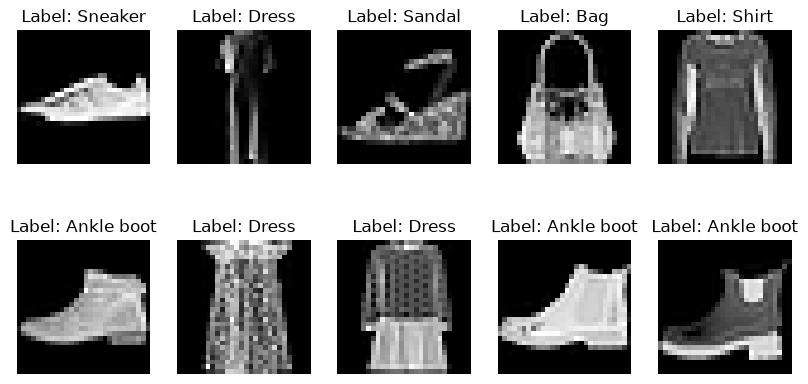

Number of training images in class 'T-shirt/top': 4798
Number of training images in class 'Trouser': 4781
Number of training images in class 'Pullover': 4795
Number of training images in class 'Dress': 4816
Number of training images in class 'Coat': 4798
Number of training images in class 'Sandal': 4789
Number of training images in class 'Shirt': 4782
Number of training images in class 'Sneaker': 4841
Number of training images in class 'Bag': 4803
Number of training images in class 'Ankle boot': 4797


In [4]:
# Task 1.1 print the shape of the training, validation, and test sets
print("Training set shape:", x_train.shape)
print("Validation set shape:", x_val.shape)
print("Test set shape:", x_test.shape)

# Task 1.2 print the number of classes and their names
num_classes = len(np.unique(y_train))
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
print("Number of classes:", num_classes)        
print("Class names:", class_names)

# task 1.3 display 10 images with their labels
plt.figure(figsize=(10, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f'Label: {class_names[y_train[i]]}')
    plt.axis('off')
plt.show()

# Task 1.4 count the training images in each class
for i in range(num_classes):
    count = np.sum(y_train == i)
    print(f"Number of training images in class '{class_names[i]}': {count}")

# Answer: Why do we normalize pixel values? Is the dataset balanced?
#   Normalizing pixel values helps in faster convergence during training and ensures that all features contribute equally to the loss function. 
#   The dataset appears to be relatively balanced, as the number of images in each class is similar.

Epoch 1/10


c:\Users\Omen\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8097 - loss: 0.5634 - val_accuracy: 0.8419 - val_loss: 0.4553
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8526 - loss: 0.4236 - val_accuracy: 0.8586 - val_loss: 0.4013
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8629 - loss: 0.3865 - val_accuracy: 0.8577 - val_loss: 0.3996
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8689 - loss: 0.3657 - val_accuracy: 0.8626 - val_loss: 0.4021
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8753 - loss: 0.3472 - val_accuracy: 0.8706 - val_loss: 0.3715
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8792 - loss: 0.3352 - val_accuracy: 0.8655 - val_loss: 0.3766
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8837 - loss: 0.3212 - val_accuracy: 0.8667 - val_loss: 0.3718
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8863 - loss: 0.3147 - val_accurac

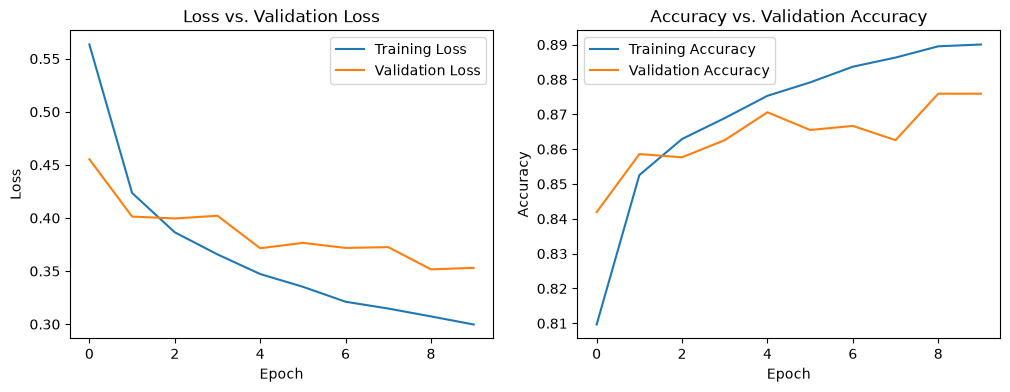

In [5]:
# Task 2.1 Build the baseline model shown above.
model = keras.Sequential([
    keras.layers.Flatten(input_shape=(28, 28)),
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
# Task 2.2 Train the model using 10 epochs
history = model.fit(x_train, y_train, epochs=10, validation_data=(x_val, y_val))

# task 2.3 Report training accuracy, validation accuracy, and final test accuracy.
train_accuracy = history.history['accuracy'][-1]
val_accuracy = history.history['val_accuracy'][-1]
test_accuracy = model.evaluate(x_test, y_test, verbose=0)[1]
print(f"Training Accuracy: {train_accuracy}")
print(f"Validation Accuracy: {val_accuracy}")
print(f"Test Accuracy: {test_accuracy}")

# Task 2.4 Plot loss vs. val_loss and accuracy vs. val_accuracy.
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss vs. Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy vs. Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# What is the purpose of Flatten, ReLU, and Softmax?
# Flatten: Converts the 2D image data into a 1D array, making it suitable for feeding into fully connected layers.
# ReLU: Introduces non-linearity into the model, allowing it to learn complex patterns.
# Softmax: Converts the output of the final layer into a probability distribution, making it suitable for multi-class classification.

# Task 3 — Analyze Predictions

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 868us/step


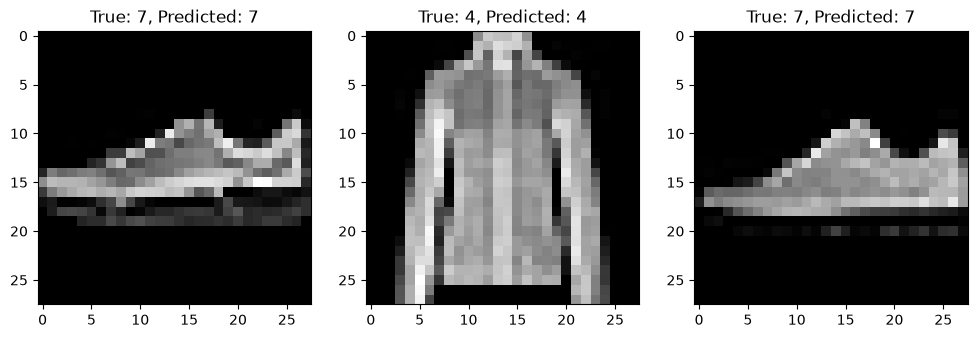

Predicted probability for true class (Image 1): 0.9979098439216614
Predicted probability for true class (Image 2): 0.7165337800979614
Predicted probability for true class (Image 3): 0.9991829991340637


In [6]:
# Task 3.1 Select 3 test images: at least one correct and one incorrect prediction (if available).
test_predictions = model.predict(x_test)
img1 = x_test[9]
img2 = x_test[57]
img3 = x_test[102]

# Task 3.2 Show each image with its true label and predicted label. 
plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.imshow(img1, cmap='gray')
plt.title(f'True: {y_test[9]}, Predicted: {test_predictions[9].argmax()}')

plt.subplot(1, 3, 2)
plt.imshow(img2, cmap='gray')
plt.title(f'True: {y_test[57]}, Predicted: {test_predictions[57].argmax()}')

plt.subplot(1, 3, 3)
plt.imshow(img3, cmap='gray')
plt.title(f'True: {y_test[102]}, Predicted: {test_predictions[102].argmax()}')
plt.show()

# Task 3.3 Show the predicted probability for the chosen class.
print(f"Predicted probability for true class (Image 1): {test_predictions[9][y_test[9]]}")
print(f"Predicted probability for true class (Image 2): {test_predictions[57][y_test[57]]}")
print(f"Predicted probability for true class (Image 3): {test_predictions[102][y_test[102]]}")

# How does the image move through the model (forward pass)?
# The image is first flattened into a 1D array, then passed through the first dense layer with ReLU activation, 
# which introduces non-linearity. The output is then passed through the second dense layer with softmax activation, 
# which produces a probability distribution over the 10 classes.

# For an incorrect prediction, what might make the two clothing classes confusing?
# Some clothing classes may have similar visual features, such as color, shape, or texture, which can lead to confusion. 


# Task 4 — Compare Epochs
####    train a fresh model each time with 5, 10, and 20 epochs. Keep everything else the same
- Plot training/validation loss and accuracy for each run.
- Compare the best validation accuracy.
- Check whether validation performance stops improving while training performance keeps improving.

Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.7997 - loss: 0.5849 - val_accuracy: 0.8354 - val_loss: 0.4775
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8478 - loss: 0.4356 - val_accuracy: 0.8462 - val_loss: 0.4319
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8595 - loss: 0.3992 - val_accuracy: 0.8608 - val_loss: 0.3946
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8647 - loss: 0.3809 - val_accuracy: 0.8636 - val_loss: 0.3824
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8720 - loss: 0.3625 - val_accuracy: 0.8663 - val_loss: 0.3837


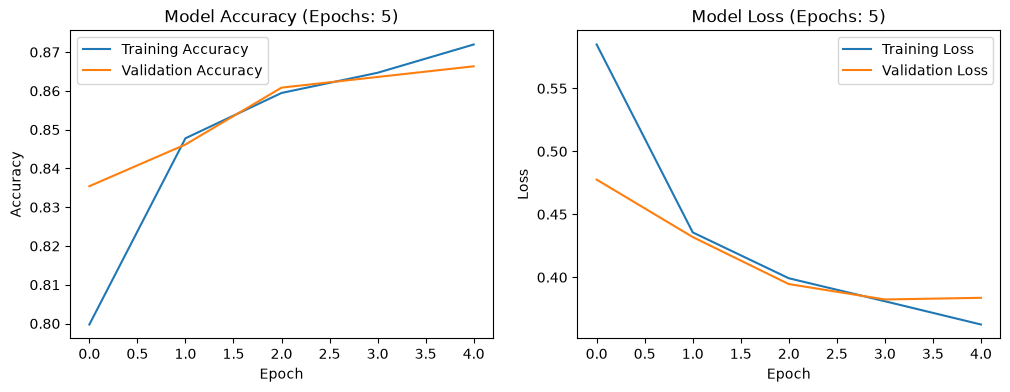

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8043 - loss: 0.5801 - val_accuracy: 0.8393 - val_loss: 0.4826
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8479 - loss: 0.4357 - val_accuracy: 0.8559 - val_loss: 0.4137
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8578 - loss: 0.4036 - val_accuracy: 0.8628 - val_loss: 0.3893
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8680 - loss: 0.3742 - val_accuracy: 0.8683 - val_loss: 0.3756
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8722 - loss: 0.3579 - val_accuracy: 0.8658 - val_loss: 0.3792
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8775 - loss: 0.3413 - val_accuracy: 0.8719 - val_loss: 0.3592
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8809 - loss: 0.3292 - val_accuracy: 0.8667 - val_loss: 0.3660
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8850 - loss: 0.3197 - 

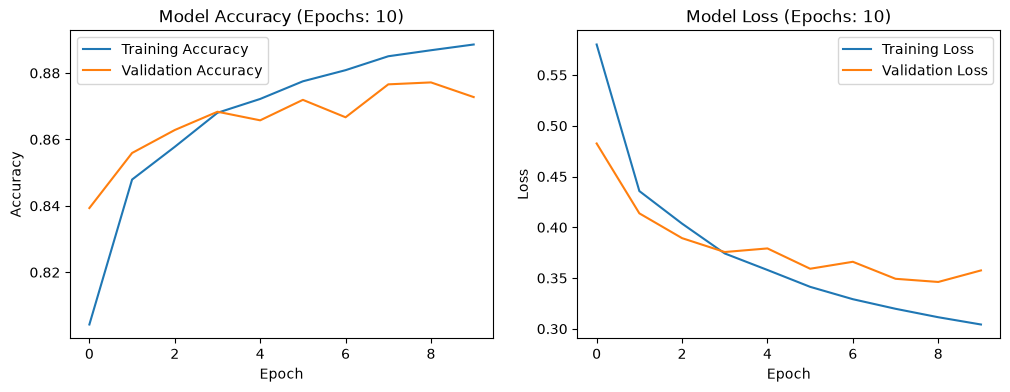

Epoch 1/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8021 - loss: 0.5762 - val_accuracy: 0.8444 - val_loss: 0.4462
Epoch 2/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8509 - loss: 0.4266 - val_accuracy: 0.8518 - val_loss: 0.4277
Epoch 3/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8618 - loss: 0.3922 - val_accuracy: 0.8510 - val_loss: 0.4140
Epoch 4/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8699 - loss: 0.3691 - val_accuracy: 0.8676 - val_loss: 0.3875
Epoch 5/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8728 - loss: 0.3520 - val_accuracy: 0.8693 - val_loss: 0.3677
Epoch 6/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8800 - loss: 0.3355 - val_accuracy: 0.8696 - val_loss: 0.3626
Epoch 7/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8834 - loss: 0.3254 - val_accuracy: 0.8637 - val_loss: 0.3854
Epoch 8/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8882 - loss: 0.3123 - 

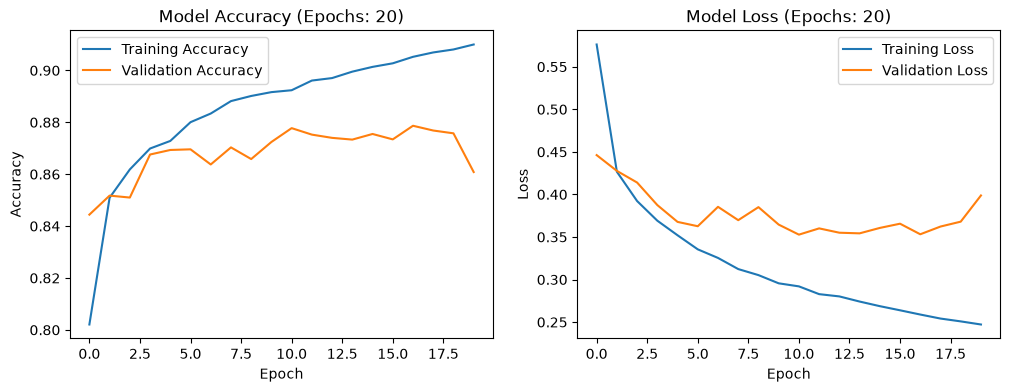

Validation Accuracies for different epochs:
Epochs: 5, Validation Accuracy: 0.8663333058357239
Epochs: 10, Validation Accuracy: 0.8771666884422302
Epochs: 20, Validation Accuracy: 0.8786666393280029


In [ ]:
epochs = [5, 10, 20]
val_accuracies = {}

for e in epochs: 
    model = keras.Sequential([
        keras.layers.Flatten(input_shape=(28, 28)),
        keras.layers.Dense(32, activation='relu'),
        keras.layers.Dense(10, activation='softmax')
    ])

    model.compile(optimizer='adam',
                loss='sparse_categorical_crossentropy',
                metrics=['accuracy'])
    history = model.fit(x_train, y_train, epochs=e, validation_data=(x_val, y_val))
    val_accuracies[e] = max(history.history['val_accuracy'])
    
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title(f'Model Accuracy (Epochs: {e})')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title(f'Model Loss (Epochs: {e})')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.show()
    
print("===========================================")
print(f"Validation Accuracies for different epochs:")
for e, acc in val_accuracies.items():
    print(f"Epochs: {e}, Validation Accuracy: {acc}")
    


## Task 5 — EarlyStopping Experiment

Use **40 epochs** as the maximum. Compare:

- **Run A:** Without `EarlyStopping`.
- **Run B:** With `EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)`.
- **Run C:** With `EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)`.

1. Record the number of epochs actually trained.
2. Compare the best validation loss and final validation accuracy.

**Answer:** What does `patience=3`,`5` mean? Why might EarlyStopping help?


In [8]:
print("Run A:")
model = keras.Sequential([
    keras.layers.Flatten(input_shape=(28, 28)),
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(
    x_train, 
    y_train, 
    epochs=40, 
    validation_data=(x_val, y_val), 
    batch_size=32
    )
num_epochs = len(history.history['accuracy'])
print(f"Number of epochs run: {num_epochs}")

best_val_loss = min(history.history['val_loss'])
print(f"Best validation loss: {best_val_loss}")
final_val_loss = history.history['val_loss'][-1]
print(f"Final validation loss: {final_val_loss}")

print("Run B:")
model = keras.Sequential([
    keras.layers.Flatten(input_shape=(28, 28)),
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
Early_stopping = keras.callbacks.EarlyStopping (
    patience = 3,
    restore_best_weights = True,
    monitor = "val_loss"
)
history = model.fit(
    x_train, 
    y_train, 
    epochs=40, 
    validation_data=(x_val, y_val), 
    batch_size=32, 
    callbacks=[Early_stopping]
    )
num_epochs = len(history.history['accuracy'])
print(f"Number of epochs run: {num_epochs}")
best_val_loss = min(history.history['val_loss'])
print(f"Best validation loss: {best_val_loss}")
final_val_loss = history.history['val_loss'][-1]
print(f"Final validation loss: {final_val_loss}")

print("Run C:")
model = keras.Sequential([
    keras.layers.Flatten(input_shape=(28, 28)),
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
Early_stopping = keras.callbacks.EarlyStopping (
    patience = 5,
    restore_best_weights = True,
    monitor = "val_loss"
)
history = model.fit(
    x_train, 
    y_train, 
    epochs=40, 
    validation_data=(x_val, y_val), 
    batch_size=32, 
    callbacks=[Early_stopping]
    )
num_epochs = len(history.history['accuracy'])
print(f"Number of epochs run: {num_epochs}")
best_val_loss = min(history.history['val_loss'])
print(f"Best validation loss: {best_val_loss}")
final_val_loss = history.history['val_loss'][-1]
print(f"Final validation loss: {final_val_loss}")



Run A:
Epoch 1/40


c:\Users\Omen\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8066 - loss: 0.5610 - val_accuracy: 0.8328 - val_loss: 0.4861
Epoch 2/40
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8499 - loss: 0.4268 - val_accuracy: 0.8554 - val_loss: 0.4160
Epoch 3/40
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8615 - loss: 0.3891 - val_accuracy: 0.8557 - val_loss: 0.4005
Epoch 4/40
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8683 - loss: 0.3665 - val_accuracy: 0.8630 - val_loss: 0.3877
Epoch 5/40
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8746 - loss: 0.3496 - val_accuracy: 0.8600 - val_loss: 0.3974
Epoch 6/40
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8789 - loss: 0.3365 - val_accuracy: 0.8648 - val_loss: 0.3769
Epoch 7/40
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8822 - loss: 0.3252 - val_accuracy: 0.8718 - val_loss: 0.3583
Epoch 8/40
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8845 - loss: 0.3158 - val_accurac

## What does patience=3,5 mean? Why might EarlyStopping help?
- #### The patience parameter in EarlyStopping specifies the number of epochs to wait for an improvement in the monitored metric (in this case, validation loss) before stopping the training.


## Task 6 — Hidden Neurons Experiment

Train fresh models with **16, 32, and 128 neurons** in the hidden layer.

1. Keep epochs, batch size, optimizer, and data split fixed.
2. Compare training and validation accuracy.
3. Record training time if possible.

**Answer:** Did adding neurons always improve validation accuracy? What is the trade-off?


In [9]:
import time

neurons = [16, 32, 128]
train_accuracies = []
val_accuracies = []
training_times = []

for neuron in neurons:
    model = keras.Sequential([
        keras.layers.Flatten(input_shape=(28, 28)),
        keras.layers.Dense(neuron, activation='relu'),
        keras.layers.Dense(10, activation='softmax')
    ])

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    Early_stopping = keras.callbacks.EarlyStopping(
        patience=5,
        restore_best_weights=True,
        monitor="val_loss"
    )

    # 1. Record start time
    start_time = time.perf_counter()

    history = model.fit(
        x_train,
        y_train,
        epochs=40,
        validation_data=(x_val, y_val),
        batch_size=32,
        callbacks=[Early_stopping]
    )

    # 2. Record end time and compute elapsed seconds
    elapsed_time = time.perf_counter() - start_time
    training_times.append(elapsed_time)

    train_accuracies.append(max(history.history['accuracy']))
    val_accuracies.append(max(history.history['val_accuracy']))

    print(f"Model ({neuron} neurons) trained in {elapsed_time:.2f} seconds.")


Epoch 1/40


c:\Users\Omen\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.7896 - loss: 0.6127 - val_accuracy: 0.8371 - val_loss: 0.4660
Epoch 2/40
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8427 - loss: 0.4495 - val_accuracy: 0.8439 - val_loss: 0.4443
Epoch 3/40
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8516 - loss: 0.4194 - val_accuracy: 0.8496 - val_loss: 0.4213
Epoch 4/40
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8592 - loss: 0.4002 - val_accuracy: 0.8468 - val_loss: 0.4231
Epoch 5/40
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8620 - loss: 0.3879 - val_accuracy: 0.8551 - val_loss: 0.4074
Epoch 6/40
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8653 - loss: 0.3786 - val_accuracy: 0.8612 - val_loss: 0.3954
Epoch 7/40
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8680 - loss: 0.3692 - val_accuracy: 0.8609 - val_loss: 0.3947
Epoch 8/40
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8704 - loss: 0.3600 - val_accurac

###  Did adding neurons always improve validation accuracy? What is the trade-off?
- ##### It did improve both accuracy and time